In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Minha primeira rede neural: duas espirais

### Objetivo

<p>Construir uma rede neural artificial do zero,</br>usando python e numpy para resolver</br> um problema de classificação de dados não lineares.</p>

<p>O experimento consiste em dois grupos de pontos</br>que possuem formato de espiral.</p>

<p>Estudar:</p>

- Criação dos dados;
- neurônios artificiais;
- pesos e vieses;
- funções de ativação;
- forward proppagation;
- backpropagation;
- atualização dos pesos;
- avaliação dos resultados.

In [2]:
# Importando tabelas necessárias: NumPy calcula e Matplotlib cria gráfico
import numpy as np
import matplotlib.pyplot as plt

# Ferramnentas para separar dados e avaliar resultados
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Criando os dados

In [3]:
# Importar as bibliotecas
import numpy as np
import matplotlib.pyplot as plt

# Definir uma semente para reproduzir os resultados
np.random.seed(42)

# Quantidade de pontos em cada espiral
pontos_por_classe = 200

# Criando os espaços para armazenar os dados
X = np.zeros((pontos_por_classe * 2, 2))
y = np.zeros(pontos_por_classe * 2)

# Criar as duas espirais
for classe in range(2):

    # Índices dos pontos de cada classe
    ix = range(
        pontos_por_classe * classe,
        pontos_por_classe * (classe + 1)
    )

    # Distância do centro
    raio = np.linspace(0.0, 1, pontos_por_classe)

    # Ângulo dos pontos
    angulo = np.linspace(
        classe * 4,
        (classe + 1) * 4,
        pontos_por_classe
    )

    # Adicionar pequenas variações aleatórias
    angulo += np.random.randn(pontos_por_classe) * 0.2

    # Calcular as coordenadas
    X[ix] = np.c_[
        raio * np.sin(angulo * 2.5),
        raio * np.cos(angulo * 2.5)
    ]

    # Identificando a classe
    y[ix] = classe

print("Dados criados com sucesso!")
print("Quantidade de pontos:", len(X))
print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

Dados criados com sucesso!
Quantidade de pontos: 400
Formato de X: (400, 2)
Formato de y: (400,)


# 2. Visualizando as duas espirais

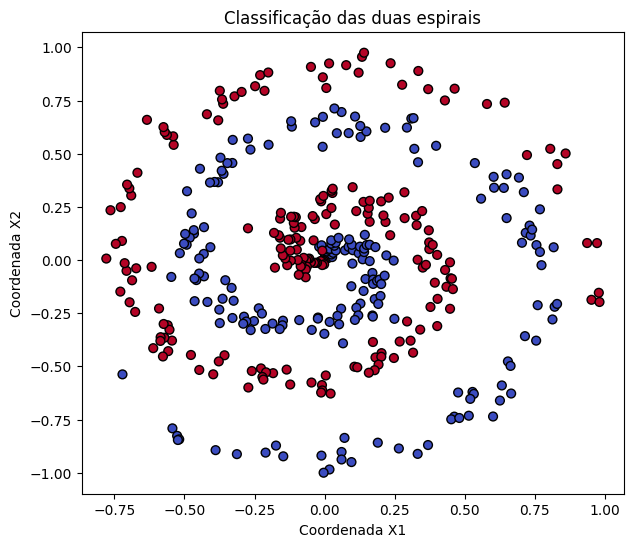

In [4]:
plt.figure(figsize=(7, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    s=40,
    edgecolors="black"
)

plt.title("Classificação das duas espirais")
plt.xlabel("Coordenada X1")
plt.ylabel("Coordenada X2")

plt.show()

# 3. Separando os dados

In [5]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Pontos para treinamento:", len(X_treino))
print("Pontos para teste:", len(X_teste))

Pontos para treinamento: 320
Pontos para teste: 80


# 4. Inicializando rede neural

In [6]:
# Camada de entrada: 2 neurônios para 16
W1 = np.random.randn(2, 16) * 0.5
b1 = np.zeros((1, 16))

# Primeira camada oculta: 16 para 16
W2 = np.random.randn(16, 16) * 0.5
b2 = np.zeros((1, 16))

# Camada de saída: 16 para 1
W3 = np.random.randn(16, 1) * 0.5
b3 = np.zeros((1, 1))

# Contando os parâmetros
total = (
    W1.size + b1.size +
    W2.size + b2.size +
    W3.size + b3.size
)

print("Total de parâmetros:", total)

Total de parâmetros: 337


# 5. Funções de ativação

In [7]:
# ReLU transforma valores negativos em zero
def relu(z):
    return np.maximum(0, z)

# Sigmoid: transforma o resultado em probabilidade
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

# 6. Propagação forward

In [8]:
def forward(X):

    # Primeira camada oculta
    h1 = relu(X @ W1 + b1)

    # Segunda camada oculta
    h2 = relu(h1 @ W2 + b2)

    # Camada de saída
    p = sigmoid(h2 @ W3 + b3).ravel()

    return h1, h2, p

# 7. Treinamento da rede neural

In [9]:
# Taxa de aprendizagem
taxa_aprendizado = 0.5

# Quantidade de treinamentos
epocas = 5000

for passo in range(epocas):

    # 1. Fazer a previsão
    h1, h2, p = forward(X_treino)

    # 2. Calcular o erro (cross-entropy)
    erro = -np.mean(
        y_treino * np.log(p + 1e-9) +
        (1 - y_treino) * np.log(1 - p + 1e-9)
    )

    # 3. Backpropagation
    d3 = (p - y_treino)[:, None] / len(y_treino)

    d2 = (d3 @ W3.T) * (h2 > 0)

    d1 = (d2 @ W2.T) * (h1 > 0)

    # 4. Atualizar os pesos e vieses
    W3 -= taxa_aprendizado * (h2.T @ d3)
    b3 -= taxa_aprendizado * d3.sum(axis=0)

    W2 -= taxa_aprendizado * (h1.T @ d2)
    b2 -= taxa_aprendizado * d2.sum(axis=0)

    W1 -= taxa_aprendizado * (X_treino.T @ d1)
    b1 -= taxa_aprendizado * d1.sum(axis=0)

    # Mostrar o progresso a cada 1000 épocas
    if (passo + 1) % 1000 == 0:

        previsoes = (p >= 0.5).astype(int)

        acuracia = np.mean(
            previsoes == y_treino
        ) * 100

        print(
            f"Epoca {passo + 1} | "
            f"Erro: {erro:.4f} | "
            f"Acuracia: {acuracia:.1f}%"
        )

print("Treinamento concluído com êxito.")

Epoca 1000 | Erro: 0.1754 | Acuracia: 94.4%
Epoca 2000 | Erro: 0.0438 | Acuracia: 98.4%
Epoca 3000 | Erro: 0.0307 | Acuracia: 98.4%
Epoca 4000 | Erro: 0.0260 | Acuracia: 98.8%
Epoca 5000 | Erro: 0.0232 | Acuracia: 98.8%
Treinamento concluído com êxito.


# 8. Teste da rede neural

In [10]:
# Fazer previsões com os dados de teste
_, _, probabilidades = forward(X_teste)

# Transformar probabilidades em classes
previsoes = (probabilidades >= 0.5).astype(int)

# Calcular a acurácia
acuracia = accuracy_score(y_teste, previsoes)

print("Resultado final:")
print(f"Acurácia: {acuracia * 100:.2f}%")

Resultado final:
Acurácia: 97.50%


# 9. Visualizando a fronteira de decisão

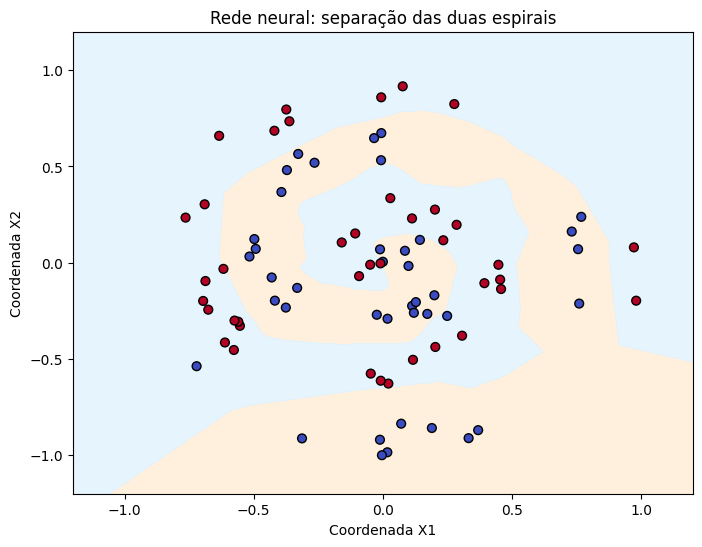

In [11]:
# Criar uma grade de coordenadas
xx, yy = np.meshgrid(
    np.linspace(-1.2, 1.2, 200),
    np.linspace(-1.2, 1.2, 200)
)

# Organizar as coordenadas em uma matriz
grade = np.c_[xx.ravel(), yy.ravel()]

# A rede faz previsões para todos os pontos da grade
_, _, probabilidades = forward(grade)

# Voltar ao formato de uma imagem
probabilidades = probabilidades.reshape(xx.shape)

# Desenhar o gráfico
plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    probabilidades,
    levels=[0, 0.5, 1],
    colors=["#ffedd5", "#e0f2fe"],
    alpha=0.8
)

plt.scatter(
    X_teste[:, 0],
    X_teste[:, 1],
    c=y_teste,
    cmap="coolwarm",
    edgecolors="black",
    s=40
)

plt.title("Rede neural: separação das duas espirais")
plt.xlabel("Coordenada X1")
plt.ylabel("Coordenada X2")

plt.show()